# 05 · Fidelity: do the forecasts match what real people did?

Notebook 04 made the forecasts without looking at the real cued trials. **This notebook compares them with reality for the first time.**

Each comparison is done for every model (rungs 0, 1, 2) and every forecast (A, B, C), on the three checks Seldon describes:

| Check | Question | Measures |
| --- | --- | --- |
| **1 · Each decision** | Do the copies choose like the real people, offer by offer? | Choice curves, choice agreement, prediction score, response times, the cue effect |
| **2 · The whole session** | Does behaviour unfold over time like it does for real people? | Time course across the session, carry-over between trials |
| **3 · Run to run** | Are the results steady when the simulation is repeated? | Every measure is computed for each of the 200 repeats and reported with its 95% range |

Every score is set against a **human reference**: how well a perfect model could possibly do, given how noisy real behaviour is.

**The headline:** for each person, the cue effect the copy predicted against the cue effect the real person showed (section 6).

Simulated trials are held to the same rule as real ones: a simulated response faster than 0.25 s or slower than 10 s is dropped. Rungs 0 and 1 have no model of time; their response times were borrowed from each person's real basic trials (notebook 04), so they serve as a "knows nothing about timing" comparison.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, "../src")
import dd, fidelity as fd, highlight as hl

QUICK = False                                   # must match the setting used in notebook 04
TAG = "quick" if QUICK else "basic"
FC_DIR = dd.ROOT / "data" / "derived" / "forecasts" / TAG
OUT = dd.ROOT / "data" / "derived" / "fidelity" / TAG; OUT.mkdir(parents=True, exist_ok=True)
RUNGS = ["rung0", "rung1", "rung2"]
FORECASTS = {"rung0": ["A", "C"], "rung1": ["A", "B_main", "B_low", "B_high", "C"], "rung2": ["A", "B_main", "B_low", "B_high", "C"]}
MAIN = ["A", "B_main", "C"]                     # the three forecasts in the figures; B_low and B_high appear in the tables
COL = {"real": "#0b0b0b", "rung0": "#8a8984", "rung1": "#eb6834", "rung2": "#2a78d6"}
NAME = {"rung0": "Rung 0 · simple statistics", "rung1": "Rung 1 · patience", "rung2": "Rung 2 · patience + decision time"}
FNAME = {"A": "A · no effect", "B_main": "B · earlier studies", "B_low": "B · small shift", "B_high": "B · large shift", "C": "C · learned from others"}
INK, MUTED, GRID, BAND = "#0b0b0b", "#52514e", "#e6e5e1", "#d9d7d0"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False, "lines.linewidth": 2})
FIG_DIR = dd.ROOT / "figures"; FIG_DIR.mkdir(exist_ok=True)
def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png"); plt.show()
def rng95(x):
    return f"{np.quantile(x, .025):.2f} to {np.quantile(x, .975):.2f}"

## 1. Load the real trials and the forecasts

The trial tables were saved by notebook 04 in the same order as the simulations, so trial *i* in the real table is trial *i* in every simulated table.

In [2]:
bt = pd.read_csv(FC_DIR / "basic_trials.csv"); ct = pd.read_csv(FC_DIR / "cued_trials.csv")
U, P = int(bt.u.max()), bt.p.nunique()
sims = {}
for rung in RUNGS:
    sims[(rung, "basic")] = fd.load_sim(FC_DIR / f"{rung}_basic.npz")
    for f in FORECASTS[rung]:
        sims[(rung, f)] = fd.load_sim(FC_DIR / f"{rung}_{f}.npz")
n_rep = sims[("rung2", "A")][0].shape[0]
dropped = {k: np.isnan(v[0]).mean() for k, v in sims.items() if k[0] == "rung2"}
print(f"{P} people · {len(bt):,} basic and {len(ct):,} cued trials · {n_rep} repeats per forecast")
print("Rung 2 simulated trials dropped by the 0.25-10 s rule:", {k[1]: f"{v:.1%}" for k, v in dropped.items()})

42 people · 8,004 basic and 7,991 cued trials · 200 repeats per forecast
Rung 2 simulated trials dropped by the 0.25-10 s rule: {'basic': '0.3%', 'A': '0.3%', 'B_main': '0.3%', 'B_low': '0.3%', 'B_high': '0.3%', 'C': '0.3%'}


## 2. The human references

A model can never match people perfectly, because people are noisy: the same person given the same offer twice will not always choose the same way. These references say what "as good as it gets" looks like, so each score can be read against it.

1. **Noise in each person's cue effect.** Each person's real cue effect (cued minus basic, averaged over their two days) rests on about 380 trials, so it is measured with error. We estimate that error by resampling each person's trials (bootstrap). A perfect model would still miss each person's measured cue effect by about this much.
2. **The best possible person-by-person correlation.** Because of that noise, even a perfect model could not correlate 1.0 with the real cue effects. The ceiling is the square root of the reliability (the share of the spread between people that is real rather than noise).
3. **Noise in the group's choice curves.** The real group's share of "later" at each reward size is itself an estimate from 42 people. Resampling people shows how far two equally valid samples of 42 would differ. A model whose curve error is this small is as close as the data can tell.

In [3]:
def per_person_effect(basic_ch, cued_ch):
    """Cue effect per person (cued minus basic share of 'later', same day, averaged over the two days)."""
    b = fd.share(basic_ch, bt.u.values - 1, U); c_ = fd.share(cued_ch, ct.u.values - 1, U)
    e = c_ - b                                              # repeats x person-days
    return 0.5 * (e[:, 0::2] + e[:, 1::2])                  # repeats x people (person-days are 2p-1, 2p)

real_eff = per_person_effect(bt.choice.values, ct.choice.values)[0]
people = bt.groupby("p").person.first().sort_index().values
se = fd.bootstrap_trial_se(pd.concat([bt, ct])).reindex(people).values
reliability = max(0.0, 1 - np.mean(se ** 2) / np.var(real_eff, ddof=1))
r_ceiling = np.sqrt(reliability)
band = 1.96 * np.median(se)

def curve_noise(codes, n, col, n_boot=1000, seed=1):
    rng = np.random.default_rng(seed); real = fd.share(ct.choice.values, codes, n)[0]; gaps = []
    for _ in range(n_boot):
        pick = rng.choice(np.arange(1, P + 1), P)
        rows = np.concatenate([np.flatnonzero(ct.p.values == p) for p in pick])
        gaps.append(100 * np.abs(fd.share(ct.choice.values[rows], codes[rows], n)[0] - real).mean())
    return np.median(gaps)
amt_codes, del_codes = ct.amount_level.values - 1, ct.delay_level.values - 1
ref = pd.Series({
    "real average cue effect (points)": 100 * real_eff.mean(),
    "typical measurement error of one person's cue effect (points)": 100 * np.median(se),
    "reliability of the per-person cue effects": reliability,
    "best possible person-by-person correlation": r_ceiling,
    "reward-size curve: gap expected from sampling 42 people (points)": curve_noise(amt_codes, 16, "amount_level"),
    "delay curve: gap expected from sampling 42 people (points)": curve_noise(del_codes, 6, "delay_level"),
})
ref.to_csv(OUT / "human_references.csv")
ref.round(3).to_frame("value")

,value
real average cue effect (points),6.306
typical measurement error of one person's cue effect (points),4.219
reliability of the per-person cue effects,0.887
best possible person-by-person correlation,0.942
reward-size curve: gap expected from sampling 42 people (points),2.150
delay curve: gap expected from sampling 42 people (points),1.782


## 3. Check 1 · Each decision

For every model and forecast, on the cued trials:

| Measure | In plain words | Better is |
| --- | --- | --- |
| **Reward-size curve error** | At each of the 16 reward sizes, the gap between the copies' and the real people's share of "later", averaged (percentage points) | Lower |
| **Delay curve error** | The same across the 6 delays | Lower |
| **Choice agreement** | Share of trials where the copy made the same choice as its real person | Higher |
| **Prediction score** | On average, the probability the copies gave to what the person actually chose (geometric mean; a coin flip scores 50%) | Higher |
| **RT quantile error** | Gap between simulated and real response times at the 10th to 90th percentiles, for "later" and "now" choices (seconds) | Lower |
| **Cue effect** | The predicted change in "later" choices from basic to cued trials, against the real change | Close to real |

Each measure is computed in each of the 200 repeats. The table shows the average, and the range covers 95% of repeats (check 3).

In [4]:
rows, eff_pred, logs = [], {}, {}
for rung in RUNGS:
    b_ch, b_rt = sims[(rung, "basic")]
    for f in FORECASTS[rung]:
        ch, rt = sims[(rung, f)]
        amt_err = fd.curve_error(ch, ct.choice.values, amt_codes, 16)
        del_err = fd.curve_error(ch, ct.choice.values, del_codes, 6)
        agree = fd.agreement(ch, ct.choice.values)
        ls = fd.log_score(ch, ct.choice.values); logs[(rung, f)] = ls
        rtq = fd.rt_quantile_error(ch, rt, ct.choice.values, ct.rt.values)
        e = per_person_effect(b_ch, ch); eff_pred[(rung, f)] = e
        med_change = np.nanmedian(rt, 1) - np.nanmedian(b_rt, 1)
        rows.append({"rung": rung, "forecast": f,
                     "reward-size curve error (pts)": amt_err.mean(), "  range": rng95(amt_err),
                     "delay curve error (pts)": del_err.mean(), "   range": rng95(del_err),
                     "choice agreement": agree.mean(),
                     "prediction score": np.exp(ls.mean()),
                     "RT quantile error (s)": rtq.mean(), "    range": rng95(rtq),
                     "predicted cue effect (pts)": 100 * e.mean(1).mean(), "     range": rng95(100 * e.mean(1)),
                     "real cue effect (pts)": 100 * real_eff.mean(),
                     "predicted change in median RT (s)": np.mean(med_change)})
check1 = pd.DataFrame(rows)
real_rt_change = np.median(ct.rt) - np.median(bt.rt)
check1["real change in median RT (s)"] = real_rt_change
check1.to_csv(OUT / "check1_each_decision.csv", index=False)
print(f"Human references: reward-size curve noise {ref.iloc[4]:.1f} pts, delay curve noise {ref.iloc[5]:.1f} pts.")
check1.round(3)

Human references: reward-size curve noise 2.1 pts, delay curve noise 1.8 pts.


,rung,forecast,reward-size curve error (pts),range,delay curve error (pts),range,choice agreement,prediction score,RT quantile error (s),range,predicted cue effect (pts),range,real cue effect (pts),predicted change in median RT (s),real change in median RT (s)
0,rung0,A,6.670,6.01 to 7.46,6.044,5.28 to 6.93,0.822,0.724,0.161,0.14 to 0.19,0.268,-0.91 to 1.49,6.306,-0.001,0.058
1,rung0,C,4.303,3.58 to 4.95,1.569,1.05 to 2.12,0.830,0.731,0.149,0.13 to 0.18,5.996,4.92 to 7.19,6.306,-0.001,0.058
2,rung1,A,6.172,5.37 to 6.96,4.936,4.10 to 5.71,0.812,0.737,0.162,0.14 to 0.19,0.105,-1.02 to 1.31,6.306,-0.002,0.058
3,rung1,B_main,5.175,4.45 to 5.94,3.272,2.51 to 4.18,0.815,0.742,0.162,0.13 to 0.18,1.766,0.66 to 2.85,6.306,-0.001,0.058
4,rung1,B_low,5.805,5.04 to 6.48,4.256,3.44 to 4.98,0.813,0.741,0.161,0.14 to 0.18,0.783,-0.50 to 1.87,6.306,-0.001,0.058
5,rung1,B_high,4.670,3.86 to 5.47,2.372,1.64 to 3.25,0.816,0.745,0.165,0.13 to 0.19,2.691,1.47 to 3.98,6.306,-0.001,0.058
6,rung1,C,4.556,4.02 to 5.27,2.182,1.46 to 3.00,0.814,0.741,0.162,0.13 to 0.18,2.878,1.79 to 3.96,6.306,-0.002,0.058
7,rung2,A,6.343,5.51 to 7.17,4.451,3.54 to 5.31,0.817,0.737,0.084,0.07 to 0.10,0.237,-1.01 to 1.41,6.306,-0.003,0.058
8,rung2,B_main,5.291,4.54 to 5.99,2.845,2.16 to 3.63,0.820,0.744,0.085,0.07 to 0.11,1.990,0.85 to 3.10,6.306,-0.007,0.058
9,rung2,B_low,5.875,5.21 to 6.59,3.779,3.04 to 4.56,0.819,0.741,0.083,0.06 to 0.10,0.931,-0.37 to 2.21,6.306,-0.005,0.058


**How to read this table.**
- Compare each curve error with the sampling noise printed above it. A curve error near the noise is as good as the data can show.
- Choice agreement and prediction score will be similar across forecasts, because most trials are easy and the cue only changes close calls. The cue effect column is where the forecasts differ.
- Rungs 0 and 1 borrow real basic-trial response times, so their RT error is the "knows nothing about timing" comparison point for rung 2.
- Forecast B changes only patience. If it gets the choice change roughly right but misses the change in response time, the cue changes *how* people decide, not just *what* they choose.

### Choice curves on the cued trials (rung 2)

Real people (dots) against the rung 2 copies under each forecast (lines; band = 95% of repeats).

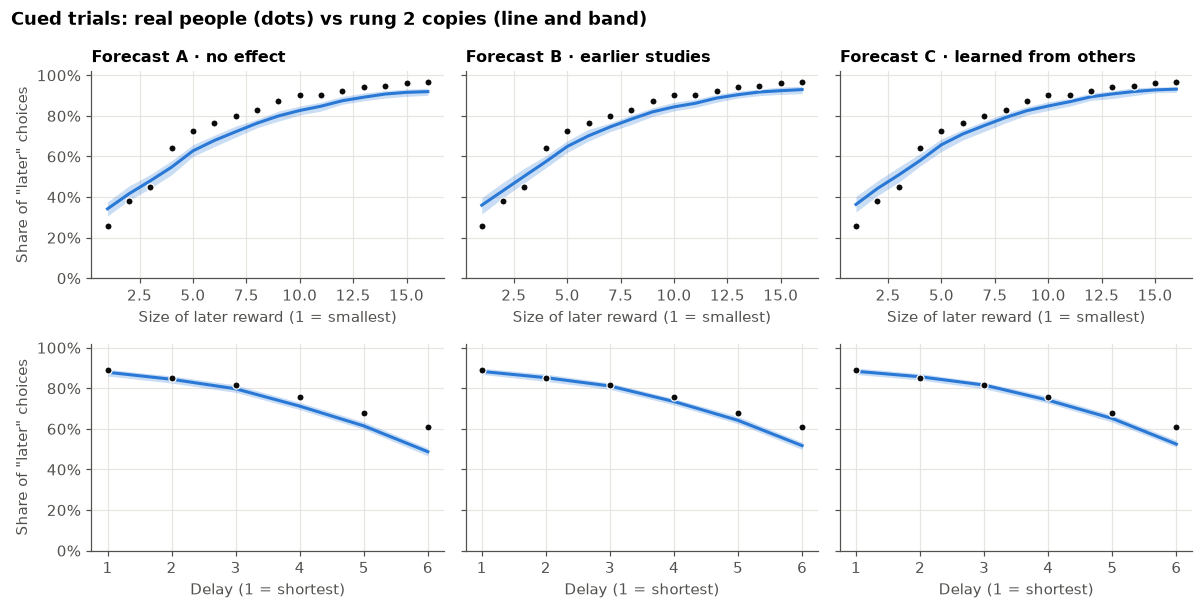

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6), sharey=True)
for j, f in enumerate(MAIN):
    ch = sims[("rung2", f)][0]
    for i, (codes, n, xl) in enumerate([(amt_codes, 16, "Size of later reward (1 = smallest)"), (del_codes, 6, "Delay (1 = shortest)")]):
        ax = axes[i, j]; x = np.arange(1, n + 1)
        s = fd.share(ch, codes, n); lo, mid, hi = np.quantile(s, [.025, .5, .975], axis=0)
        ax.fill_between(x, lo, hi, color=COL["rung2"], alpha=0.25, lw=0); ax.plot(x, mid, color=COL["rung2"])
        ax.scatter(x, fd.share(ct.choice.values, codes, n)[0], s=22, color=COL["real"], zorder=3, edgecolor="white", linewidth=0.8)
        ax.set_xlabel(xl); ax.set_ylim(0, 1.02)
        if i == 0: ax.set_title(f"Forecast {FNAME[f]}")
        if j == 0: ax.set_ylabel('Share of "later" choices'); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
fig.suptitle("Cued trials: real people (dots) vs rung 2 copies (line and band)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "05_cued_choice_curves")

### Response times on the cued trials (rung 2)

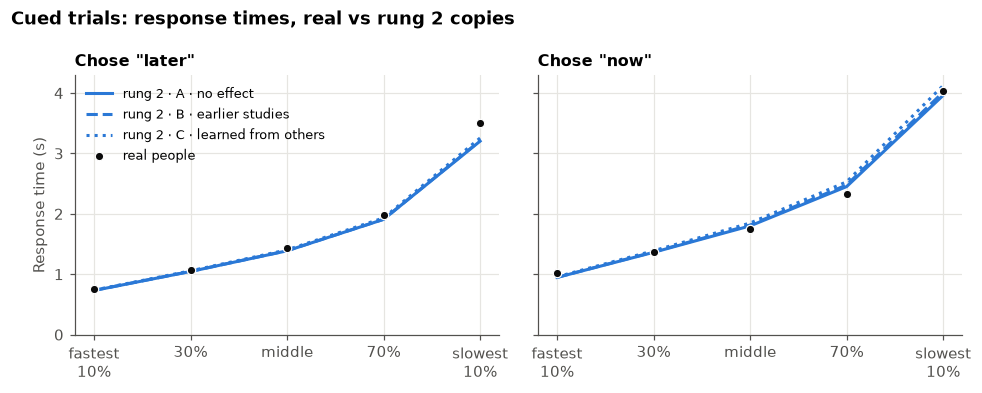

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, (cc, lab) in zip(axes, [(1, 'Chose "later"'), (0, 'Chose "now"')]):
    real = np.quantile(ct.rt[ct.choice == cc], fd.QS)
    for f, ls_ in zip(MAIN, ["-", "--", ":"]):
        ch, rt = sims[("rung2", f)]
        q = np.array([np.nanquantile(np.where(ch[r] == cc, rt[r], np.nan), fd.QS) for r in range(len(ch))]).mean(0)
        ax.plot(range(5), q, color=COL["rung2"], ls=ls_, label=f"rung 2 · {FNAME[f]}")
    ax.scatter(range(5), real, s=30, color=COL["real"], zorder=3, edgecolor="white", linewidth=0.8, label="real people")
    ax.set_xticks(range(5)); ax.set_xticklabels(["fastest\n10%", "30%", "middle", "70%", "slowest\n10%"]); ax.set_title(lab)
axes[0].set_ylim(0, max(a.get_ylim()[1] for a in axes)); axes[0].set_ylabel("Response time (s)"); axes[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("Cued trials: response times, real vs rung 2 copies", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "05_cued_rt_quantiles")

## 4. Check 2 · The whole session

**Time course.** Each session is cut into 8 blocks of 24 trials (counting basic and cued trials together, in the order shown). For the cued trials in each block: the typical response time and the share of "later" choices, real against rung 2.

Rung 2 has no practice effect and no attention states, so its copies should stay flat while real people speed up. That gap is what rung 3 is for.

**Carry-over.** Do slow responses follow slow responses? This is the correlation between each trial's response time and the next one's, using all trials in the order shown, after removing each person's level in each block (so the overall speed-up is not counted). Real attention drifts slowly, so real people should show some carry-over. Rung 2 treats every trial as independent.

One technical note: removing each block's level pulls this measure slightly below zero. With 24 trials per block, completely independent trials score about −0.04, not 0. So compare real people with rung 2's value, not with zero.

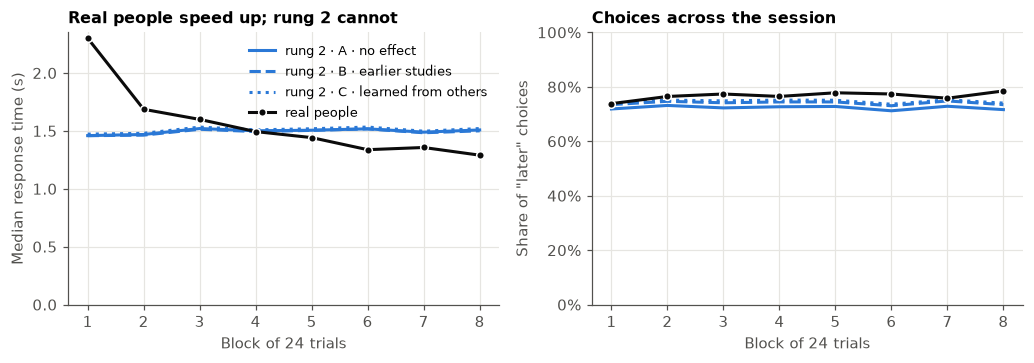

In [7]:
block = (ct.trial_in_session.values - 1) // 24
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
for ax, what, yl in [(axes[0], "rt", "Median response time (s)"), (axes[1], "choice", 'Share of "later" choices')]:
    real = [np.median(ct.rt[block == k]) if what == "rt" else ct.choice[block == k].mean() for k in range(8)]
    for f, ls_ in zip(MAIN, ["-", "--", ":"]):
        ch, rt = sims[("rung2", f)]; x = rt if what == "rt" else ch
        sim = np.array([[np.nanmedian(x[r, block == k]) if what == "rt" else np.nanmean(x[r, block == k]) for k in range(8)] for r in range(len(x))])
        ax.plot(range(1, 9), sim.mean(0), color=COL["rung2"], ls=ls_, label=f"rung 2 · {FNAME[f]}")
    ax.plot(range(1, 9), real, color=COL["real"], marker="o", ms=5, markeredgecolor="white", label="real people")
    ax.set_xlabel("Block of 24 trials"); ax.set_ylabel(yl); ax.set_ylim(0, None if what == "rt" else 1)
axes[0].set_title("Real people speed up; rung 2 cannot"); axes[1].set_title("Choices across the session")
axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); axes[0].legend(fontsize=8.5)
fig.tight_layout(); save(fig, "05_session_time_course")

In [8]:
full = pd.concat([bt.assign(src="basic", i=np.arange(len(bt))), ct.assign(src="cued", i=np.arange(len(ct)))])
order = np.lexsort((full.trial_in_session.values, full.u.values))
full = full.iloc[order]
unit_o, block_o = full.u.values, (full.trial_in_session.values - 1) // 24
real_co = fd.carry_over(full.rt.values, unit_o, block_o)[0]
co_rows = [{"who": "real people", "carry-over": real_co, "range (95% of repeats)": ""}]
for f in FORECASTS["rung2"]:
    b_rt, c_rt = sims[("rung2", "basic")][1], sims[("rung2", f)][1]
    sim_full = np.concatenate([b_rt, c_rt], axis=1)[:, order]
    co = fd.carry_over(sim_full, unit_o, block_o)
    co_rows.append({"who": f"rung 2 · {FNAME[f]}", "carry-over": co.mean(), "range (95% of repeats)": rng95(co)})
check2 = pd.DataFrame(co_rows); check2.to_csv(OUT / "check2_carry_over.csv", index=False)
check2.round(3)

,who,carry-over,range (95% of repeats)
0,real people,0.065,
1,rung 2 · A · no effect,-0.041,-0.06 to -0.03
2,rung 2 · B · earlier studies,-0.041,-0.06 to -0.03
3,rung 2 · B · small shift,-0.041,-0.06 to -0.02
4,rung 2 · B · large shift,-0.042,-0.06 to -0.03
5,rung 2 · C · learned from others,-0.042,-0.06 to -0.03


## 5. Does more psychology help? Comparing the models

For each forecast, two comparisons, each with a 95% interval from resampling people (5,000 times). A model "helps" only if the interval excludes zero.

- **Prediction score:** does the richer model give more probability to what people actually chose? (Each person's average log score; positive = the richer model is better.)
- **Cue-effect error:** does the richer model predict each person's cue effect more closely? (Each person's absolute error in points; positive = the richer model is better.)

In [9]:
def person_mean(x):
    return pd.Series(x).groupby(ct.p.values).mean().sort_index().values
pairs = [("rung1", "rung0", f) for f in ["A", "C"]] + [("rung2", "rung1", f) for f in ["A", "B_main", "B_low", "B_high", "C"]]
cmp_rows = []
for rich, simple, f in pairs:
    d_log = person_mean(logs[(rich, f)]) - person_mean(logs[(simple, f)])
    err = lambda r: np.abs(eff_pred[(r, f)].mean(0) - real_eff)
    d_err = 100 * (err(simple) - err(rich))
    for name, v in [("prediction score (log)", d_log), ("cue-effect error (pts)", d_err)]:
        m, lo, hi = fd.bootstrap_people(v)
        cmp_rows.append({"comparison": f"{rich} vs {simple}", "forecast": f, "measure": name,
                         "improvement": m, "95% interval": f"{lo:.3f} to {hi:.3f}", "helps?": "yes" if lo > 0 else ("worse" if hi < 0 else "no clear difference")})
compare = pd.DataFrame(cmp_rows); compare.to_csv(OUT / "model_comparison.csv", index=False)
compare.round(3)

,comparison,forecast,measure,improvement,95% interval,helps?
0,rung1 vs rung0,A,prediction score (log),0.017,-0.007 to 0.046,no clear difference
1,rung1 vs rung0,A,cue-effect error (pts),-0.066,-0.212 to 0.071,no clear difference
2,rung1 vs rung0,C,prediction score (log),0.013,-0.007 to 0.035,no clear difference
3,rung1 vs rung0,C,cue-effect error (pts),0.999,-0.086 to 2.012,no clear difference
4,rung2 vs rung1,A,prediction score (log),0.000,-0.007 to 0.008,no clear difference
5,rung2 vs rung1,A,cue-effect error (pts),0.070,-0.048 to 0.187,no clear difference
6,rung2 vs rung1,B_main,prediction score (log),0.002,-0.007 to 0.011,no clear difference
7,rung2 vs rung1,B_main,cue-effect error (pts),0.020,-0.122 to 0.170,no clear difference
8,rung2 vs rung1,B_low,prediction score (log),-0.001,-0.008 to 0.008,no clear difference
9,rung2 vs rung1,B_low,cue-effect error (pts),0.073,-0.029 to 0.186,no clear difference


## 6. The headline: predicted vs real cue effect, person by person

One dot per person. Horizontal: how much the cue really changed their share of "later" choices (cued minus basic, averaged over their two days). Vertical: how much their copy predicted.

- **Dots on the diagonal** = perfect prediction.
- **The grey band** = measurement noise. Each person's real cue effect rests on about 380 trials, so even a perfect model would land outside this band about 1 time in 20.
- **r** = correlation between predicted and real, against the **best possible r** given that noise.

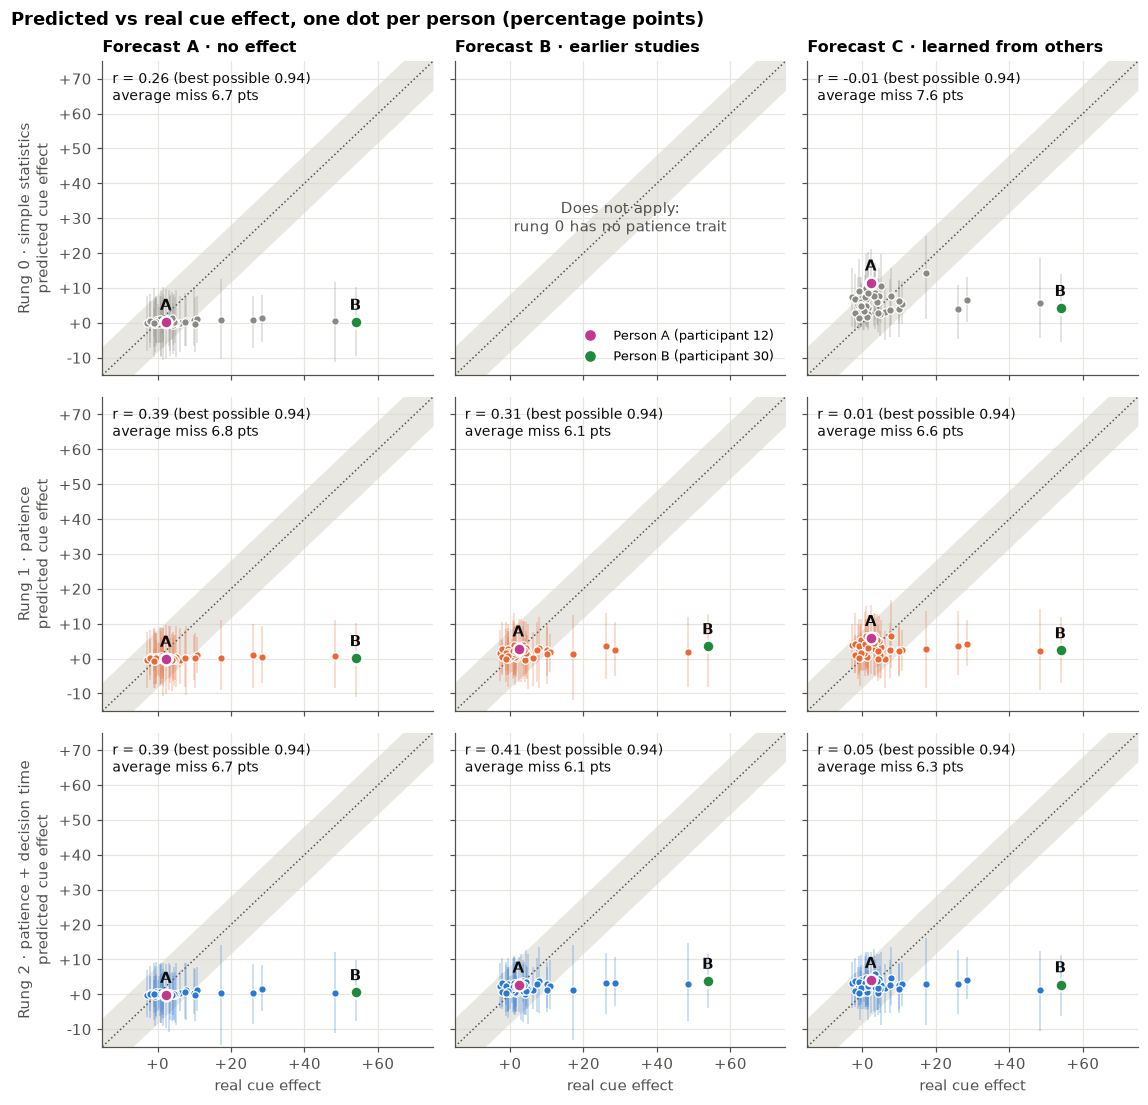

,rung,forecast,r (predicted vs real),best possible r,average miss (pts),share of people inside the noise band
0,rung0,A,0.263,0.942,6.712,0.810
1,rung0,C,-0.007,0.942,7.567,0.762
2,rung1,A,0.390,0.942,6.779,0.810
3,rung1,B_main,0.311,0.942,6.106,0.833
4,rung1,C,0.007,0.942,6.568,0.857
5,rung2,A,0.389,0.942,6.709,0.810
6,rung2,B_main,0.414,0.942,6.085,0.833
7,rung2,C,0.047,0.942,6.310,0.857


In [10]:
fig, axes = plt.subplots(3, 3, figsize=(10.5, 10.2), sharex=True, sharey=True)
lim = [min(-0.15, real_eff.min() - 0.03), max(0.75, real_eff.max() + 0.03)]
head_rows = []
for i, rung in enumerate(RUNGS):
    for j, f in enumerate(MAIN):
        ax = axes[i, j]
        ax.fill_between(lim, [lim[0] - band, lim[1] - band], [lim[0] + band, lim[1] + band], color=BAND, alpha=0.6, lw=0)
        ax.plot(lim, lim, color=MUTED, lw=1, ls=":")
        if (rung, f) not in eff_pred:
            ax.text(0.5, 0.5, "Does not apply:\nrung 0 has no patience trait", transform=ax.transAxes, ha="center", va="center", color=MUTED)
        else:
            e = eff_pred[(rung, f)]; pred = e.mean(0); lo, hi = np.quantile(e, [.025, .975], axis=0)
            ax.vlines(real_eff, lo, hi, color=COL[rung], alpha=0.3, lw=1)
            ax.scatter(real_eff, pred, s=24, color=COL[rung], edgecolor="white", linewidth=0.8, zorder=3)
            r = np.corrcoef(real_eff, pred)[0, 1] if pred.std() > 0 else np.nan
            mae = 100 * np.abs(pred - real_eff).mean()
            inside = np.mean(np.abs(pred - real_eff) <= band)
            head_rows.append({"rung": rung, "forecast": f, "r (predicted vs real)": r, "best possible r": r_ceiling,
                              "average miss (pts)": mae, "share of people inside the noise band": inside})
            idx = {l: list(people).index(p) for l, p in hl.present(people).items()}
            hl.mark(ax, {l: (real_eff[i_], pred[i_]) for l, i_ in idx.items()}, size=60)
            ax.text(0.03, 0.97, f"r = {r:.2f} (best possible {r_ceiling:.2f})\naverage miss {mae:.1f} pts", transform=ax.transAxes, va="top", fontsize=9, color=INK)
        ax.set_xlim(lim); ax.set_ylim(lim)
        if i == 0: ax.set_title(f"Forecast {FNAME[f]}")
        if j == 0: ax.set_ylabel(f"{NAME[rung]}\npredicted cue effect")
        if i == 2: ax.set_xlabel("real cue effect")
for ax in axes.ravel():
    ax.xaxis.set_major_formatter(lambda v, _: f"{v*100:+.0f}"); ax.yaxis.set_major_formatter(lambda v, _: f"{v*100:+.0f}")
fig.suptitle("Predicted vs real cue effect, one dot per person (percentage points)", x=0.01, ha="left", fontweight="bold")
axes[0, 1].legend(handles=hl.handles(), loc="lower right", fontsize=8.5)
fig.tight_layout(); save(fig, "05_headline_cue_effect_per_person")
headline = pd.DataFrame(head_rows); headline.to_csv(OUT / "headline.csv", index=False)
headline.round(3)

## 7. Two robustness checks

**Without person 25.** Person 25 is much slower than everyone else (notebook 01). The headline numbers are recomputed without them.

**Future vs past cue.** The forecasts pool both cues. Here the real and predicted cue effects are shown separately for each cue type.

In [11]:
keep = people != 25
rows = []
for (rung, f), e in eff_pred.items():
    pred = e.mean(0)
    rows.append({"rung": rung, "forecast": f, "r, all people": np.corrcoef(real_eff, pred)[0, 1] if pred.std() > 0 else np.nan,
                 "r, without person 25": np.corrcoef(real_eff[keep], pred[keep])[0, 1] if pred[keep].std() > 0 else np.nan,
                 "average miss, all (pts)": 100 * np.abs(pred - real_eff).mean(),
                 "average miss, without person 25 (pts)": 100 * np.abs(pred[keep] - real_eff[keep]).mean()})
pd.DataFrame(rows).round(3)

,rung,forecast,"r, all people","r, without person 25","average miss, all (pts)","average miss, without person 25 (pts)"
0,rung0,A,0.263,0.272,6.712,6.858
1,rung0,C,-0.007,-0.023,7.567,7.743
2,rung1,A,0.390,0.395,6.779,6.918
3,rung1,B_main,0.311,0.306,6.106,6.236
4,rung1,B_low,0.435,0.431,6.429,6.557
5,rung1,B_high,0.240,0.232,6.178,6.316
6,rung1,C,0.007,-0.007,6.568,6.707
7,rung2,A,0.389,0.392,6.709,6.848
8,rung2,B_main,0.414,0.410,6.085,6.216
9,rung2,B_low,0.500,0.497,6.356,6.487


In [12]:
cue_of_unit = ct.groupby("u").condition.first().sort_index().values
def effect_by_cue(basic_ch, cued_ch):
    e = fd.share(cued_ch, ct.u.values - 1, U) - fd.share(basic_ch, bt.u.values - 1, U)
    return {cue: 100 * e[:, cue_of_unit == cue].mean(1) for cue in ["future", "past"]}
real_by_cue = effect_by_cue(bt.choice.values, ct.choice.values)
rows = []
for (rung, f) in eff_pred:
    pc = effect_by_cue(sims[(rung, "basic")][0], sims[(rung, f)][0])
    rows.append({"rung": rung, "forecast": f,
                 "future cue: predicted (pts)": pc["future"].mean(), "future cue: real (pts)": real_by_cue["future"][0],
                 "past cue: predicted (pts)": pc["past"].mean(), "past cue: real (pts)": real_by_cue["past"][0]})
pd.DataFrame(rows).round(2)

,rung,forecast,future cue: predicted (pts),future cue: real (pts),past cue: predicted (pts),past cue: real (pts)
0,rung0,A,0.12,6.28,0.41,6.33
1,rung0,C,5.67,6.28,6.32,6.33
2,rung1,A,-0.15,6.28,0.36,6.33
3,rung1,B_main,1.50,6.28,2.03,6.33
4,rung1,B_low,0.53,6.28,1.03,6.33
5,rung1,B_high,2.39,6.28,2.99,6.33
6,rung1,C,2.63,6.28,3.13,6.33
7,rung2,A,0.10,6.28,0.37,6.33
8,rung2,B_main,1.88,6.28,2.10,6.33
9,rung2,B_low,0.78,6.28,1.08,6.33


## Saved files

In `data/derived/fidelity/basic/`: `human_references.csv`, `check1_each_decision.csv`, `check2_carry_over.csv`, `model_comparison.csv`, `headline.csv`. Figures in `figures/` start with `05_`.

## What to look for

1. **Forecast A vs B vs C, cue effect column:** how much the cue matters, and how much knowing its size helps.
2. **Forecast B, response times:** B changes only patience. If real people's response times change with the cue and B's do not, the cue changes how people decide, not just what they choose.
3. **Rung 1 vs rung 0, rung 2 vs rung 1:** does more psychology predict better?
4. **The headline figure:** is the per-person r anywhere near the best possible r? Who sits far from the diagonal: the few strong responders?
5. **Session time course and carry-over:** what rung 2 misses, and whether rung 3 is worth building.